In [6]:
import os
import cv2 as cv
import sys
import time
import numpy as np
import pandas as pd
import mediapipe
import matplotlib.pyplot as plt
#from .autonotebook import tqdm as notebook_tqdm
import torch
import torch.nn as nn
import torch.optim as optim
import torchinfo
import optuna # --> Fine tuning model's parameters
## Pytorch's computer vision library
import torchvision
import torchmetrics
from torchvision import datasets # --> We will use HMDB51 dataset for this project
import torchvision.transforms as transforms
import torchvision.transforms.v2 as T
from torch.utils.data import DataLoader , Subset # --> This allows us to extract a portion of our data insteas of the entire set
import video_player1 as vp1
## Results are reproducible
torch.manual_seed(42)
print('code run above successfully')

code run above successfully


## Data from HMDB will be combined with our collected data

In [ ]:
HMDB_path = "./videos/HMDB51"
HMDB_annotation_path = "./videos/HMDB51_annotations"

if not os.path.exists(HMDB_path) or not os.path.exists(HMDB_annotation_path):
    os.makedirs(HMDB_path , exist_ok = True)
    os.makedirs(HMDB_annotation_path, exist_ok = True)
    print("Directories created successfully")
else:
    print("Directories already exist")

transform = T.Compose([
    T.ToImage(),

    T.ToDtype(torch.float32 , scale = True)
])

selected_classes = ['pushup', 'pullup']
train_dataset = datasets.HMDB51(root = HMDB_path , annotation_path = HMDB_annotation_path, 
                                fold = 1, train = True ,transform  = transform ,
                                frames_per_clip = 16, num_workers = 3 , step_between_clips = 16)

## We shall indices from of the respective classes
selected_indices = [idx 
                    for idx , ( _ , labels) in enumerate(train_dataset)
                      if train_dataset.classes[labels] in selected_classes] # --> us list comprehension

train_subset = Subset(train_dataset , selected_indices)

Directories already exist


FileNotFoundError: Couldn't find any class folder in ./videos/HMDB51.

In [4]:
dataset_path = "C:\\Users\\Simon\\OneDrive\\Desktop\\Pytorch\\videos"

In [ ]:


# Check through a function the structure of the data in our folder
def check_folder():
    data = dataset_path
    for root , sub_folder , files in os.walk(dataset_path):
        level = root.replace(dataset_path , "").count(os.sep)
        indent = "  " * 4
        print(f"{indent}{os.path.basename(root)}")
        for file in files[:5]:
            print(f"{indent}     {file}")
check_folder()

        videos
        Back_workout
             3 Cable Exercises for a BIGGER Back.mp4
             4 Facepull Mistakes You Need to FIX!.mp4
             Are You Making This Pullup Mistake？!.mp4
             Barbell Row Grip Widths & Muscles Worked.mp4
             Build 3D Shoulders (Hit Every Head!).mp4
        bicep_exercises
             #raka.bulder_.92#trending #gym #like #positime#trending #bulder#viralshorts #likeandsubscribe.mp4
             3 #bicep Exercises You've Probably Never Heard Of.mp4
             3 Best Long Head Bicep Exercises for a Bigger Peak.mp4
             3 Bicep Exercises You Can Add to Your Routine #homeworkout #fitness #motivation #gym #biceps.mp4
             45 Min Back &  Bicep Workout.mp4
        core_exercises
             30 Minute Core Workout For Strong Core ｜ Pilates for Beginners.mp4
             30 Minute Core Workout ｜ Intermediate Pilates.mp4
             Ab Workouts Are Pointless.mp4
             Abs Exercise You Are Missing...mp4
        

Our data orginally had inconsistent names so we shall standardize the names

In [4]:
# Function to standardize function names 
def change_names(dataset):
    for root , subfolder , files in os.walk(dataset):
        f_name =  os.path.basename(root)

        if root == dataset:
            continue
        # This section is for replacing file name with a consistent one based on the sub folder of the files but maintain the format
        for i , file in enumerate(files , start = 1):
            # replace name and extension
            name , extension = os.path.splitext(file)
            # Construct old path turns out we can't replace with just the file name
            old_path = os.path.join(root , file)
            # Construct new path
            new = f"{f_name}_0{i}_{extension}"
            new_path = os.path.join(root , new)
            # Repalce file name 
            os.replace(old_path , new_path)
change_names(dataset_path)

## EDA


In [8]:
## OpenCv is preferred for video metadata,I used AI to help me understand it's prefernce over pytorch
results = [] # --> stores metadata for each video
corrupted_videos = []
for root , subfolder , files in os.walk(dataset_path):
    ## Extract name of the folder/s in our dataset path
    action_path = os.path.basename(root)

    if root == dataset_path:
        continue
    ## Extract metadata from our video files
    for file in files:
        video_path = os.path.join(root,file)
        if not video_path.endswith(".mp4"):
            corrupted_videos.append(video_path)
            continue
        # Positional argument inside videocapture should be the absolute fiie path of file
        captured = cv.VideoCapture(video_path)
        if  not captured.isOpened() :
            corrupted_videos.append(captured)
            print(f"Error opening {video_path}")

            continue
        frames = captured.get(cv.CAP_PROP_FRAME_COUNT)
        height = int(captured.get(cv.CAP_PROP_FRAME_HEIGHT))
        width = int(captured.get(cv.CAP_PROP_FRAME_WIDTH))
        fps = captured.get(cv.CAP_PROP_FPS)
        duration = int(frames / fps if fps > 0 else 0)
        vp1.video_player(video_path , fps , captured , frames).play()

        results.append({
        "Video_path": video_path ,"Video": file , "Action_path" : action_path ,'Frame':frames , "FPS":fps , "Duration_in_seconds": duration , "Height":height , "Width": width})
    captured.release()

df = pd.DataFrame(results)
df.head()

TypeError: unsupported operand type(s) for /: 'float' and 'set'

In [33]:
print("Dataset Summary\n")
df.describe()

Dataset Summary



,Frame,FPS,Duration_in_seconds,Height,Width
count,167.000000,167.000000,167.000000,167.000000,167.000000
mean,2717.299401,28.592412,98.005988,565.928144,431.137725
std,8542.670338,2.383438,314.740599,123.596485,121.786002
min,153.000000,23.959242,5.000000,360.000000,360.000000
25%,323.500000,25.000000,10.000000,360.000000,360.000000
50%,613.000000,29.970000,21.000000,640.000000,360.000000
75%,1444.500000,30.000000,55.500000,640.000000,560.000000
max,55513.000000,30.000000,2148.000000,640.000000,640.000000


array([[<Axes: title={'center': 'Frame'}>,
        <Axes: title={'center': 'FPS'}>],
       [<Axes: title={'center': 'Duration_in_seconds'}>,
        <Axes: title={'center': 'Height'}>],
       [<Axes: title={'center': 'Width'}>, <Axes: >]], dtype=object)

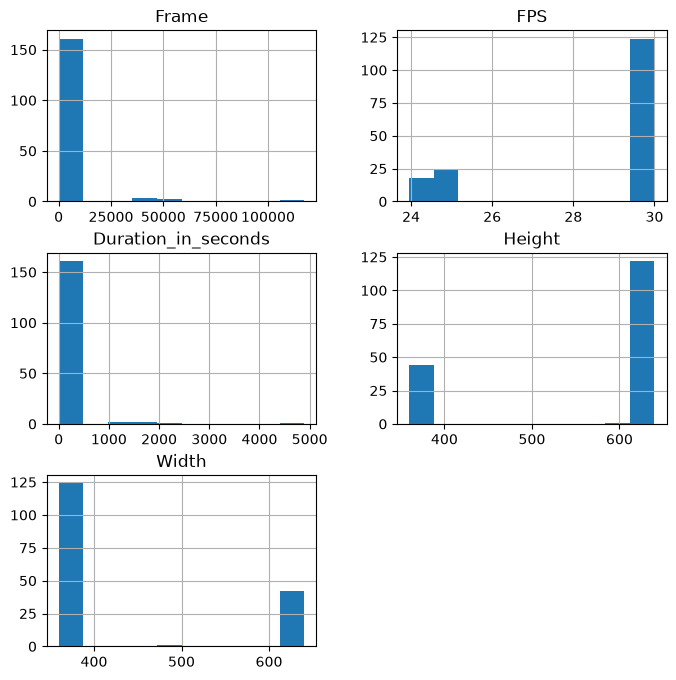

In [28]:
df.hist(figsize = (8,8))

In [34]:
df.groupby('Action_path')[["FPS" , "Duration_in_seconds"]].mean().reset_index()

,Action_path,FPS,Duration_in_seconds
0,Back_workout,28.277457,37.222222
1,bicep_exercises,29.982091,21.454545
2,core_exercises,27.208902,675.888889
3,forearm_exercises,29.573338,19.750000
4,handstand_exercises,27.890266,49.631579
5,l_sit_exercises,28.897602,25.400000
6,leg_exercises,29.650002,33.000000
7,planche_exercises,28.286211,474.200000
8,push_up_exercises,29.203571,62.285714
9,squat_exercises,26.986513,90.250000


Identify the longest videos (outliers which skew the mean)

In [35]:
df.sort_values("Duration_in_seconds", ascending =  False )[["Action_path","Video","FPS","Duration_in_seconds"]].head(10)

,Action_path,Video,FPS,Duration_in_seconds
107,planche_exercises,planche_exercises_012_.mp4,23.976024,2148
114,planche_exercises,planche_exercises_019_.mp4,23.976024,2002
38,core_exercises,core_exercises_01_.mp4,29.970030,1852
39,core_exercises,core_exercises_02_.mp4,29.970030,1548
46,core_exercises,core_exercises_09_.mp4,29.970030,1237
40,core_exercises,core_exercises_03_.mp4,29.970030,1203
110,planche_exercises,planche_exercises_015_.mp4,29.970030,235
122,push_up_exercises,push_up_exercises_016_.mp4,30.000000,234
121,push_up_exercises,push_up_exercises_015_.mp4,24.000000,217
86,leg_exercises,leg_exercises_018_.mp4,29.970030,213


The 2002 second video skew the mean and those beyond 1000s

In [36]:
df.groupby("Action_path")["Duration_in_seconds"].agg(
    ["count", "min", "median", "mean", "max"]
)

,count,min,median,mean,max
Action_path,,,,,
Back_workout,27,5,13.0,37.222222,212
bicep_exercises,11,6,12.0,21.454545,51
core_exercises,9,29,59.0,675.888889,1852
forearm_exercises,12,5,19.0,19.750000,41
handstand_exercises,19,6,48.0,49.631579,132
l_sit_exercises,10,11,15.5,25.400000,89
leg_exercises,18,6,14.0,33.000000,213
planche_exercises,10,5,67.5,474.200000,2148
push_up_exercises,14,5,35.0,62.285714,234


In [1]:
print("Hello World")

Hello World


## Build CNN Architecture.

In [ ]:
class CalisthenicsDataset(nn.Module):
    def __init__(self):
        super().__init__()

